In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("modelling.csv")

In [3]:
df['Open'].unique()

array([1])

## Feature Engineering

In the Rossman Sales dataset PromoInterval tells us which months recurring promotion (promo 2) is running.
If a store participates in Promo2 (meaning the Promo2 column is 1), it doesn't run the promotion every single day of the year. Instead, the promotion runs in a 3-month repeating cycle.

IsPromo2Active- tells the model whether a store's recurring promotion (Promo2) is active on a particular date.
-equals 1 when the store participates in Promo2, the programme has started, and the month is listed in PromoInterval. Otherwise, it equals 0.


In [4]:
df['Date'] = pd.to_datetime(df['Date'])

# Months in which the store starts a new Promo2 promotion
df['IsPromo2Active'] = df.apply(
    lambda row: int(
        row['Promo2'] == 1
        and pd.notna(row['PromoInterval'])
        and row['Date'].strftime('%b') in row['PromoInterval'].split(',')
        and row['Date'].isocalendar().year * 100
            + row['Date'].isocalendar().week
            >= row['Promo2SinceYear'] * 100
            + row['Promo2SinceWeek']
    ) if pd.notna(row['Promo2SinceYear'])
        and pd.notna(row['Promo2SinceWeek'])
        else 0,
    axis=1
)


In [5]:
df['IsPromo2Active'].unique()

array([0, 1])

Day 7 is adjacent to day 1 of the week (eg. monday is adjacent to sunday but the numbers make it seem like they are far apart)
So using sin/cos of month/dayofweek makes the month/dayofweek cyclic
sin and cos are used because for some values sin is 0 and for those values sin is not 0
This may imporve the performance of an mlp

In [6]:
# Day of week: 7-day cycle
df['DayOfWeek_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7)
df['DayOfWeek_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7)

# Month: 12-month cycle
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

In [7]:
# Remove open because all the stores we have in our final dataset is open

X = df[['DayOfWeek_sin',
    'DayOfWeek_cos',
    'Month_sin',
    'Month_cos',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'StoreType',
    'Assortment',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear',
    'Promo2',
    'Promo2SinceWeek',
    'Promo2SinceYear',
    'Year',
    'Month',
    'Day',
    'WeekOfYear',
    'IsPromo2Active',
    'Store']]
Y = df['Sales']



##Scaling/One-hot encoding


In [8]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd

import pandas as pd

# 1. Create Date and sort chronologically
df = df.copy()
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])
df = df.sort_values('Date').reset_index(drop=True)

# 2. Use the last 4 weeks (28 days) for testing
latest_date = df['Date'].max()
cutoff = latest_date - pd.Timedelta(weeks=4)

train_df = df[df['Date'] < cutoff].copy()
test_df = df[df['Date'] >= cutoff].copy()

# 3. Check the split
print("Training period:", train_df['Date'].min(), "to", train_df['Date'].max())
print("Testing period:", test_df['Date'].min(), "to", test_df['Date'].max())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("Training unique dates:", train_df['Date'].nunique())
print("Testing unique dates:", test_df['Date'].nunique())

# 3. Define target and features
target_col = 'Sales'

categorical_cols = [
    'StateHoliday', 'StoreType', 'Assortment', 'Store'
]

numerical_cols = [
    'DayOfWeek_sin', 'DayOfWeek_cos',
    'Month_sin', 'Month_cos',
    'CompetitionDistance',
    'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear',
    'Promo2SinceWeek', 'Promo2SinceYear',
    'Year', 'Month', 'Day', 'WeekOfYear'
]

binary_cols = [
    'Open', 'Promo', 'SchoolHoliday',
    'Promo2', 'IsPromo2Active'
]

feature_cols = categorical_cols + numerical_cols + binary_cols

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_test = test_df[target_col].copy()

# 4. One-hot encode categorical variables
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = pd.DataFrame(
    encoder.fit_transform(X_train[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

# 5. Standardise numerical variables
scaler = StandardScaler()

X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train[numerical_cols]),
    columns=numerical_cols,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    scaler.transform(X_test[numerical_cols]),
    columns=numerical_cols,
    index=X_test.index
)

# 6. Keep binary variables unchanged
X_train_bin = X_train[binary_cols].copy()
X_test_bin = X_test[binary_cols].copy()

# 7. Combine processed features
X_train_processed = pd.concat(
    [X_train_num, X_train_cat, X_train_bin], axis=1
)

X_test_processed = pd.concat(
    [X_test_num, X_test_cat, X_test_bin], axis=1
)

# 8. Verify alignment and shapes
assert X_train_processed.columns.equals(X_test_processed.columns)
assert X_train_processed.index.equals(y_train.index)
assert X_test_processed.index.equals(y_test.index)

print("Processed train:", X_train_processed.shape)
print("Processed test:", X_test_processed.shape)
print("Cutoff date:", pd.Timestamp(cutoff))


Training period: 2013-01-01 00:00:00 to 2015-07-02 00:00:00
Testing period: 2015-07-03 00:00:00 to 2015-07-31 00:00:00
Train shape: (169376, 27)
Test shape: (5624, 27)
Training unique dates: 913
Testing unique dates: 29
Processed train: (169376, 252)
Processed test: (5624, 252)
Cutoff date: 2015-07-03 00:00:00


In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Check for missing values
print("Missing values in training features:",
      X_train_processed.isna().sum().sum())

print("Missing values in test features:",
      X_test_processed.isna().sum().sum())

Missing values in training features: 0
Missing values in test features: 0


##MLP

In [10]:
from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(
 hidden_layer_sizes= (20),
 activation = 'relu',
 solver = 'adam',
 max_iter = 5000,
 early_stopping=True,
 random_state = 0,
 n_iter_no_change=20
)
mlp.fit(X_train_processed, y_train)

,loss,'squared_error'
,hidden_layer_sizes,20
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,5000
,shuffle,True


In [11]:
Y_pred_test = mlp.predict(X_test_processed)
Y_pred_train = mlp.predict(X_train_processed)

In [12]:
# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(y_train, Y_pred_train)
train_rmse = root_mean_squared_error(y_train, Y_pred_train)
train_r2 = r2_score(y_train,Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(y_test, Y_pred_test)
test_rmse = root_mean_squared_error(y_test, Y_pred_test)
test_r2 = r2_score(y_test, Y_pred_test)

In [13]:
print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")

--- Training Metrics ---
MAE : 1191.5631423405218
RMSE: 1687.3727203210096
R2  : 0.7897608709311934

--- Testing Metrics ---
MAE : 1143.1177390319558
RMSE: 1614.0977545242645
R2  : 0.7811583576643641


##Multivariate Linear Regression


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [15]:
linear = LinearRegression()  # Instantatiate the linear regression model
linear.fit(X_train_processed,y_train)  # Fit the model parameters to the training data.

# Evaluate model performance.
training_predictions = linear.predict(X_train_processed)  # Get model predictions for both.
testing_predictions = linear.predict(X_test_processed)    # training and testing data.

# Create a table of the various scores.
results = pd.DataFrame({
    "R^2": {
        "train": r2_score(y_train, training_predictions),
        "test": r2_score(y_test, testing_predictions)
    },
    "RMSE": {
        "train": root_mean_squared_error(y_train, training_predictions),
        "test": root_mean_squared_error(y_test, testing_predictions)
    },
    "MAE": {
        "train": mean_absolute_error(y_train, training_predictions),
        "test": mean_absolute_error(y_test, testing_predictions)
    }
})

In [16]:
Y_pred_test = mlp.predict(X_test_processed)
Y_pred_train = mlp.predict(X_train_processed)

In [17]:
print(results)

            R^2         RMSE          MAE
train  0.706807  1992.648818  1455.836881
test   0.714033  1845.111951  1363.006452


In [18]:
feature_names = X_train_processed.columns.tolist() # write the column names to a list

# create a Series for which the rows are the feature names and the data is
# the regression coefficient values
coefficients = pd.Series(data=linear.coef_.transpose(), index=feature_names)
print(coefficients)

DayOfWeek_sin          1.791470e+02
DayOfWeek_cos          6.048732e+02
Month_sin              8.751225e+02
Month_cos              3.072071e+01
CompetitionDistance   -6.161463e+02
                           ...     
Open                  -5.684342e-13
Promo                  3.339025e+03
SchoolHoliday          5.955622e+02
Promo2                -2.213339e+02
IsPromo2Active        -1.411176e+02
Length: 252, dtype: float64


##Ridge_2


In [19]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [20]:

# Alpha values
alfas = np.logspace(-2, 2, num=21)

# Store training and testing metrics
ridge_results = []

for alfa in alfas:
    ridge = Ridge(alpha=alfa, random_state=1235)

    # Train model
    ridge.fit(X_train_processed, y_train)

    # Predictions
    train_preds = ridge.predict(X_train_processed)
    test_preds = ridge.predict(X_test_processed)

    # Calculate metrics
    ridge_results.append({
        'Alpha': alfa,
        'Training R2': r2_score(y_train, train_preds),
        'Testing R2': r2_score(y_test, test_preds),
        'Training RMSE': np.sqrt(mean_squared_error(y_train, train_preds)),
        'Testing RMSE': np.sqrt(mean_squared_error(y_test, test_preds)),
        'Training MAE': mean_absolute_error(y_train, train_preds),
        'Testing MAE': mean_absolute_error(y_test, test_preds)
    })

# Convert results into a DataFrame
ridge_results = pd.DataFrame(ridge_results)

# Display all results
print("Ridge Regression Results:")
print(ridge_results.round(4).to_string(index=False))

# Find alpha with the highest testing R2
best_ridge_idx = ridge_results['Testing R2'].idxmax()
best_ridge = ridge_results.loc[best_ridge_idx]

print("\nBest Ridge Model:")
print(f"Alpha: {best_ridge['Alpha']:.4f}")
print(f"Training R2: {best_ridge['Training R2']:.4f}")
print(f"Testing R2: {best_ridge['Testing R2']:.4f}")
print(f"Training RMSE: {best_ridge['Training RMSE']:.4f}")
print(f"Testing RMSE: {best_ridge['Testing RMSE']:.4f}")
print(f"Training MAE: {best_ridge['Training MAE']:.4f}")
print(f"Testing MAE: {best_ridge['Testing MAE']:.4f}")


Ridge Regression Results:
   Alpha  Training R2  Testing R2  Training RMSE  Testing RMSE  Training MAE  Testing MAE
  0.0100       0.7068      0.7140      1992.6488     1845.1120     1455.8363    1363.0058
  0.0158       0.7068      0.7140      1992.6488     1845.1121     1455.8360    1363.0054
  0.0251       0.7068      0.7140      1992.6488     1845.1122     1455.8355    1363.0048
  0.0398       0.7068      0.7140      1992.6488     1845.1123     1455.8347    1363.0038
  0.0631       0.7068      0.7140      1992.6488     1845.1125     1455.8335    1363.0023
  0.1000       0.7068      0.7140      1992.6488     1845.1128     1455.8315    1362.9998
  0.1585       0.7068      0.7140      1992.6489     1845.1133     1455.8284    1362.9960
  0.2512       0.7068      0.7140      1992.6490     1845.1142     1455.8235    1362.9898
  0.3981       0.7068      0.7140      1992.6492     1845.1156     1455.8157    1362.9801
  0.6310       0.7068      0.7140      1992.6497     1845.1181     1455.80

##Lasoo_2

In [21]:

# Store training and testing metrics
lasso_results = []

for alfa in alfas:
    lasso = Lasso(alpha=alfa, max_iter=10000)

    # Train model
    lasso.fit(X_train_processed, y_train)

    # Predictions
    train_preds = lasso.predict(X_train_processed)
    test_preds = lasso.predict(X_test_processed)

    # Calculate metrics
    lasso_results.append({
        'Alpha': alfa,
        'Training R2': r2_score(y_train, train_preds),
        'Testing R2': r2_score(y_test, test_preds),
        'Training RMSE': np.sqrt(mean_squared_error(y_train, train_preds)),
        'Testing RMSE': np.sqrt(mean_squared_error(y_test, test_preds)),
        'Training MAE': mean_absolute_error(y_train, train_preds),
        'Testing MAE': mean_absolute_error(y_test, test_preds)
    })

# Convert results into a DataFrame
lasso_results = pd.DataFrame(lasso_results)

# Display all results
print("Lasso Regression Results:")
print(lasso_results.round(4).to_string(index=False))

# Find alpha with the highest testing R2
best_lasso_idx = lasso_results['Testing R2'].idxmax()
best_lasso = lasso_results.loc[best_lasso_idx]

print("\nBest Lasso Model:")
print(f"Alpha: {best_lasso['Alpha']:.4f}")
print(f"Training R2: {best_lasso['Training R2']:.4f}")
print(f"Testing R2: {best_lasso['Testing R2']:.4f}")
print(f"Training RMSE: {best_lasso['Training RMSE']:.4f}")
print(f"Testing RMSE: {best_lasso['Testing RMSE']:.4f}")
print(f"Training MAE: {best_lasso['Training MAE']:.4f}")
print(f"Testing MAE: {best_lasso['Testing MAE']:.4f}")


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.873e+10, tolerance: 2.294e+08
  model = cd_fast.enet_coordinate_descent(


Lasso Regression Results:
   Alpha  Training R2  Testing R2  Training RMSE  Testing RMSE  Training MAE  Testing MAE
  0.0100       0.7068      0.7141      1992.6502     1845.0463     1455.8143    1362.8916
  0.0158       0.7068      0.7141      1992.6522     1845.0129     1455.8010    1362.8258
  0.0251       0.7068      0.7141      1992.6574     1844.9558     1455.7814    1362.7200
  0.0398       0.7068      0.7141      1992.6703     1844.8700     1455.7545    1362.5603
  0.0631       0.7068      0.7141      1992.7027     1844.7457     1455.7225    1362.3134
  0.1000       0.7068      0.7142      1992.7838     1844.5733     1455.6969    1361.9371
  0.1585       0.7067      0.7143      1992.9803     1844.3558     1455.7032    1361.3686
  0.2512       0.7066      0.7143      1993.4376     1844.1478     1455.8303    1360.5745
  0.3981       0.7063      0.7143      1994.5375     1844.4006     1456.4106    1359.7624
  0.6310       0.7054      0.7137      1997.2609     1846.0388     1458.31

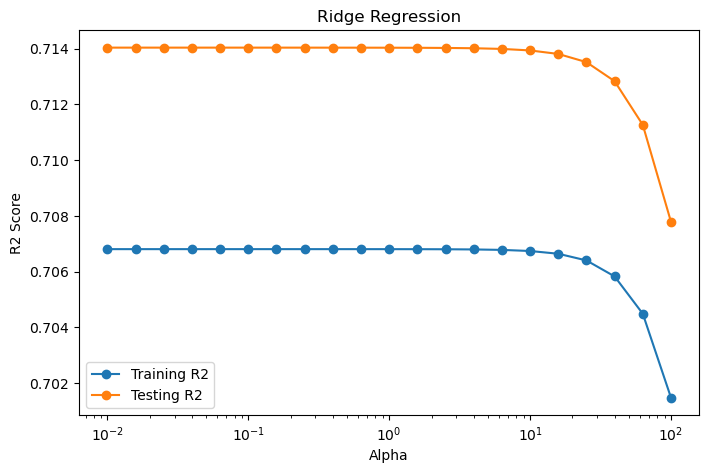

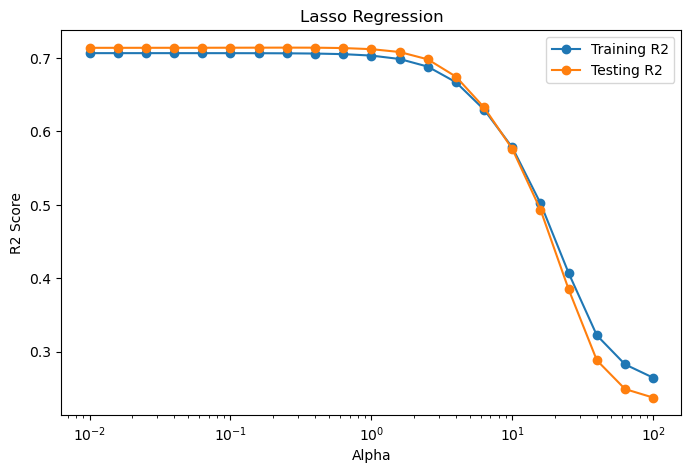

In [22]:

# Ridge plot
plt.figure(figsize=(8, 5))
plt.plot(ridge_results['Alpha'], ridge_results['Training R2'],
         marker='o', label='Training R2')
plt.plot(ridge_results['Alpha'], ridge_results['Testing R2'],
         marker='o', label='Testing R2')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Ridge Regression')
plt.legend()
plt.show()

# Lasso plot
plt.figure(figsize=(8, 5))
plt.plot(lasso_results['Alpha'], lasso_results['Training R2'],
         marker='o', label='Training R2')
plt.plot(lasso_results['Alpha'], lasso_results['Testing R2'],
         marker='o', label='Testing R2')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Lasso Regression')
plt.legend()
plt.show()


In [23]:
comparison = pd.DataFrame({
    'Model': ['Ridge', 'Lasso'],
    'Alpha': [best_ridge['Alpha'], best_lasso['Alpha']],
    'Training R2': [best_ridge['Training R2'],
                    best_lasso['Training R2']],
    'Testing R2': [best_ridge['Testing R2'],
                   best_lasso['Testing R2']],
    'Training RMSE': [best_ridge['Training RMSE'],
                      best_lasso['Training RMSE']],
    'Testing RMSE': [best_ridge['Testing RMSE'],
                     best_lasso['Testing RMSE']],
    'Training MAE': [best_ridge['Training MAE'],
                     best_lasso['Training MAE']],
    'Testing MAE': [best_ridge['Testing MAE'],
                    best_lasso['Testing MAE']]
})

print(comparison.round(4).to_string(index=False))

Model  Alpha  Training R2  Testing R2  Training RMSE  Testing RMSE  Training MAE  Testing MAE
Ridge 0.0100       0.7068      0.7140      1992.6488     1845.1120     1455.8363    1363.0058
Lasso 0.2512       0.7066      0.7143      1993.4376     1844.1478     1455.8303    1360.5745


##Ridge Regression



In [24]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

Optimal alpha is 0.010
Training score with optimal alpha is 0.707
Testing score with optimal alpha is 0.714


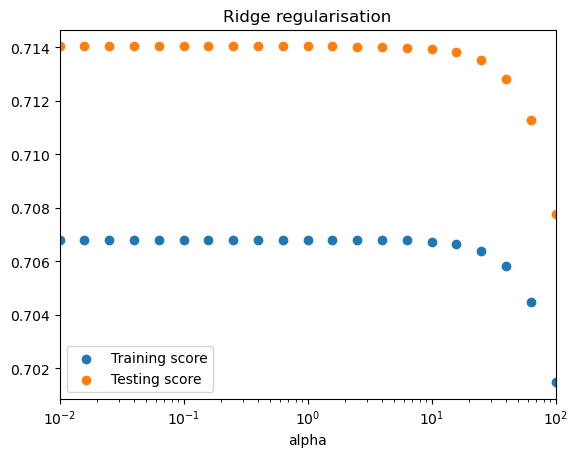

In [25]:
# create an array of 21 alpha values logarithmically distributed between 10**(-2) and 10**2
alfas = np.logspace(-2, 2, num=21)

# create two arrays for storage of the same size as alfas, but filled with zeros
ridge_training_score = np.zeros_like(alfas)
ridge_rsquared = np.zeros_like(alfas)
ridge_score = np.zeros_like(alfas)

# loop over the values in the alfas array, at each loop the current value is alfa
# and idx is incremented by 1, starting at 0
for idx, alfa in enumerate(alfas):
    ridge = Ridge(alpha=alfa, random_state=1235) # instantatiate Ridge regularisation with the current alfa
    ridge.fit(X_train_processed,y_train) # train the model to our data set
# calculate the training score and store in the array ridge_training_score
    ridge_training_score[idx] = ridge.score(X_train_processed, y_train)
    preds_linear = ridge.predict(X_test_processed) # calculate the model prediction for the test data
# calculate the correlation between the predicted and actual test data and store in the  array ridge_rsquared
    ridge_rsquared[idx] = r2_score(y_test, preds_linear)

plt.scatter(alfas, ridge_training_score, label = 'Training score') # plot the training score against alpha
plt.scatter(alfas, ridge_rsquared, label = 'Testing score') # plot the testing score against alpha
plt.xscale('log') # make the x-axis a logarithmic scale
plt.gca().set_xlim(left=.01, right=100); # fix the x-axis limits
plt.title('Ridge regularisation')
plt.xlabel('alpha');
plt.legend(loc = 'best');

opt_alfa_pos = np.argmax(ridge_rsquared)
opt_alfa = alfas[opt_alfa_pos]
print(f'Optimal alpha is {opt_alfa:.3f}')
print(f'Training score with optimal alpha is {ridge_training_score[opt_alfa_pos]:.3f}')
print(f'Testing score with optimal alpha is {ridge_rsquared[opt_alfa_pos]:.3f}')

##Lasso regularisation

In [ ]:
# create two arrays for storage of the same size as alfas, but filled with zeros
lasso_training_score = np.zeros_like(alfas)
lasso_rsquared = np.zeros_like(alfas)
alfas = np.logspace(-2, 2, num=11)
# loop over the values in the alfas array, at each loop the current value is alfa
# and idx is incremented by 1, starting at 0
for idx, alfa in enumerate(alfas):
    lasso = Lasso(alpha=alfa, max_iter = 8000) # instantatiate Lasso regularisation with the current alfa
    lasso.fit(X_train_processed,y_train) # train the model to our data set
# calculate the training score and store in the array lasso_training_score
    lasso_training_score[idx] = lasso.score(X_train_processed,y_train)
    preds_linear = lasso.predict(X_test_processed) # calculate the model prediction for the test data
# calculate the correlation between the predicted and actual test data and store in the  array lasso_rsquared
    lasso_rsquared[idx] = r2_score(y_test,preds_linear)

plt.scatter(alfas, lasso_training_score, label = 'Training score') # plot the training score against alpha
plt.scatter(alfas, lasso_rsquared, label = 'Testing score') # plot the testing score against alpha
plt.xscale('log') # make the x-axis a logarithmic scale
plt.gca().set_xlim(left = .01, right = 100); # fix the x-axis limits
plt.title('Lasso regularisation')
plt.xlabel('alpha');
plt.legend(loc='best');

opt_alfa_pos = np.argmax(lasso_rsquared)
opt_alfa = alfas[opt_alfa_pos]
print(f'Optimal alpha is {opt_alfa:.3f}')
print(f'Training score with optimal alpha is {lasso_training_score[opt_alfa_pos]:.3f}')
print(f'Testing score with optimal alpha is {lasso_rsquared[opt_alfa_pos]:.3f}')

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.630e+10, tolerance: 2.294e+08
  model = cd_fast.enet_coordinate_descent(


In [ ]:
lasso_training_score

##Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
forest = RandomForestRegressor(
    n_estimators=128,
    criterion='squared_error',
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features=1.0,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    bootstrap=True,
    oob_score=False,
    n_jobs=4,
    random_state=35,
    verbose=0,
    warm_start=False
)


In [ ]:
forest.fit(X_train_processed, y_train)

In [ ]:
Y_pred_test = forest.predict(X_test_processed)
Y_pred_train = forest.predict(X_train_processed)

In [ ]:
# 2. Evaluate Training Set Metrics
train_mae = mean_absolute_error(y_train, Y_pred_train)
train_rmse = root_mean_squared_error(y_train, Y_pred_train)
train_r2 = r2_score(y_train,Y_pred_train)


# 3. Evaluate Testing Set Metrics
test_mae = mean_absolute_error(y_test, Y_pred_test)
test_rmse = root_mean_squared_error(y_test, Y_pred_test)
test_r2 = r2_score(y_test, Y_pred_test)

In [ ]:
print("--- Training Metrics ---")
print(f"MAE : {train_mae}")
print(f"RMSE: {train_rmse}")
print(f"R2  : {train_r2}\n")

print("--- Testing Metrics ---")
print(f"MAE : {test_mae}")
print(f"RMSE: {test_rmse}")
print(f"R2  : {test_r2}")

In [ ]:
importances = pd.Series(forest.feature_importances_)
print(importances)

importances.plot(kind='barh', figsize=(8, 6))
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##LightGBM

Uses ensemble of decision trees like random forest, but
- random forest uses bagging
- LightGBM uses boosting as its core ensemble strategy
- LightGBM trees are fitting by optimising a loss function
- Unlike random forest LightGBM splits the leaves that offers the greates reduction in loss. This can produce a more accurate tree for a given number of leaves, but also more complex, unbalanced trees that overfit if left unconstrained.
- in random forest trees are build indpendently, in LighGBM trees are built sequentialy

Random Forest: Ask many independent decision trees for their predictions, then average them to obtain a more stable result.

LightGBM: Build a first prediction, examine how wrong the ensemble is, add a tree to reduce that error, and repeat.

In [ ]:
pip install lightgbm

In [ ]:
from lightgbm import LGBMRegressor as lgb

In [ ]:
lgbm = lgb(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

lgbm.fit(X_train_processed, y_train)



In [ ]:
predictions = lgbm.predict(X_test_processed)
train = lgbm.predict(X_train_processed)
print("Scores for traning ")

print("R²:", r2_score(y_train, train))
print("MAE:", mean_absolute_error(y_train, train))
print("RMSE:", root_mean_squared_error(y_train, train))

print("Scores for testing")
print("R²:", r2_score(y_test, predictions))
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", root_mean_squared_error(y_test, predictions))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

# Original, unencoded test features
X_test_original = test_df[feature_cols].copy()

# Combine preprocessing into a prediction function
def predict_original(X):
    X = X.copy()

    # Apply the already-fitted encoder
    X_cat = pd.DataFrame(
        encoder.transform(X[categorical_cols]),
        columns=encoder.get_feature_names_out(categorical_cols),
        index=X.index
    )

    # Apply the already-fitted scaler
    X_num = pd.DataFrame(
        scaler.transform(X[numerical_cols]),
        columns=numerical_cols,
        index=X.index
    )

    # Keep binary variables unchanged
    X_bin = X[binary_cols].copy()

    # Reconstruct features in the same order used for training
    X_processed = pd.concat(
        [X_num, X_cat, X_bin], axis=1
    )

    X_processed = X_processed[X_train_processed.columns]

    return lgbm.predict(X_processed)


# Calculate baseline test MSE
baseline_mse = mean_squared_error(
    y_test, predict_original(X_test_original)
)

# Shuffle each ORIGINAL feature as a whole
rng = np.random.default_rng(42)
n_repeats = 10
importance_results = []

for col in feature_cols:
    mse_increases = []

    for _ in range(n_repeats):
        X_permuted = X_test_original.copy()

        X_permuted[col] = rng.permutation(
            X_permuted[col].to_numpy()
        )

        permuted_mse = mean_squared_error(
            y_test, predict_original(X_permuted)
        )

        mse_increases.append(permuted_mse - baseline_mse)

    importance_results.append({
        "Feature": col,
        "Importance": np.mean(mse_increases),
        "Std": np.std(mse_increases, ddof=1)
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.to_string(index=False))

# Plot the top 20 original features
plot_df = (
    importance_df.nlargest(20, "Importance")
    .sort_values("Importance")
)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    color="steelblue",
    edgecolor="black",
    capsize=3
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Increase in Test MSE after permutation")
ax.set_ylabel("Original Feature")
ax.set_title("LightGBM Permutation Importance")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
# Add predictions alongside the actual test data
daily_df = pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

# Aggregate sales across all stores for each date
daily_df = (
    daily_df.groupby("Date", as_index=False)[["Actual", "Predicted"]]
    .sum()
    .sort_values("Date")
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_df["Date"], daily_df["Actual"],
    label="Actual", color="steelblue"
)

plt.plot(
    daily_df["Date"], daily_df["Predicted"],
    label="Predicted", color="orangered"
)

plt.title("Actual vs Predicted Total Daily Sales (LightGBM)")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()